In [1]:
import pandas as pd
df = pd.read_csv('./data/train.csv')
df.head()

,id,loanAmnt,term,interestRate,installment,grade,subGrade,employmentTitle,employmentLength,homeOwnership,...,n5,n6,n7,n8,n9,n10,n11,n12,n13,n14
0,0,35000.0,5,19.52,917.97,E,E2,320.0,2 years,2,...,9.0,8.0,4.0,12.0,2.0,7.0,0.0,0.0,0.0,2.0
1,1,18000.0,5,18.49,461.90,D,D2,219843.0,5 years,0,...,NaN,NaN,NaN,NaN,NaN,13.0,NaN,NaN,NaN,NaN
2,2,12000.0,5,16.99,298.17,D,D3,31698.0,8 years,0,...,0.0,21.0,4.0,5.0,3.0,11.0,0.0,0.0,0.0,4.0
3,3,11000.0,3,7.26,340.96,A,A4,46854.0,10+ years,1,...,16.0,4.0,7.0,21.0,6.0,9.0,0.0,0.0,0.0,1.0
4,4,3000.0,3,12.99,101.07,C,C2,54.0,NaN,1,...,4.0,9.0,10.0,15.0,7.0,12.0,0.0,0.0,0.0,4.0


In [2]:
# 确保issueDate是日期格式
df['issueDate'] = pd.to_datetime(df['issueDate'])

# 提取年份和月份
df['issueYearMonth'] = df['issueDate'].dt.to_period('M')

# 计算每月坏客户比例
monthly_default_rate = df.groupby('issueYearMonth')['isDefault'].mean()

# 将Series转换为DataFrame
monthly_default_rate_df = monthly_default_rate.to_frame(name='DefaultRate')

# 重置索引以使issueYearMonth成为DataFrame的列
monthly_default_rate_df.reset_index(inplace=True)

monthly_default_rate_df.head()

,issueYearMonth,DefaultRate
0,2007-06,0.000000
1,2007-07,0.000000
2,2007-08,0.173913
3,2007-09,0.285714
4,2007-10,0.269231


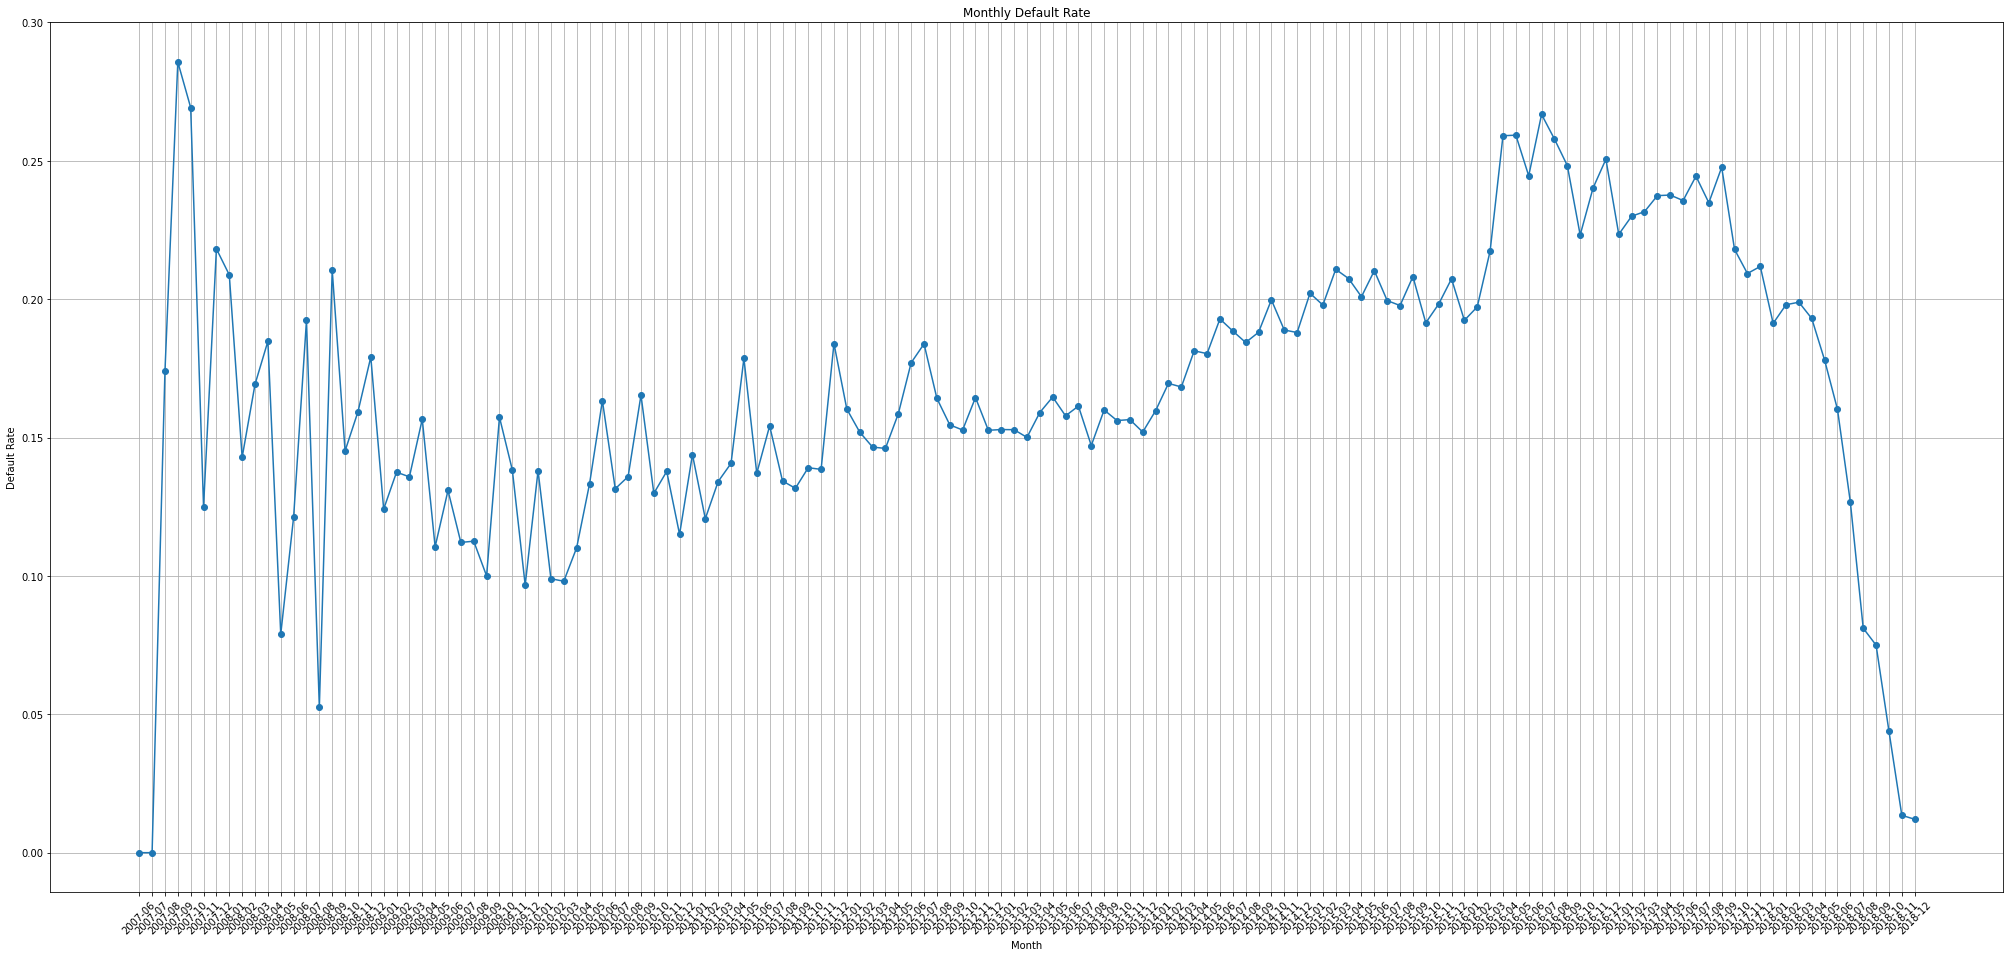

In [3]:
import matplotlib.pyplot as plt
#设置中文显示
# plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
# plt.rcParams['font.sans-serif'] = ['Heiti TC']
# plt.rcParams['font.sans-serif'] = ['Songti SC']
# plt.rcParams['font.sans-serif'] = ['Xingkai SC']
# plt.rcParams['axes.unicode_minus'] = False
# 绘制线图
plt.figure(figsize=(35, 16))
plt.plot(monthly_default_rate_df['issueYearMonth'].astype(str), monthly_default_rate_df['DefaultRate'], marker='o')
# plt.title('违约率（月）')
# plt.xlabel('月份')
# plt.ylabel('违约率')
plt.title('Monthly Default Rate')
plt.xlabel('Month')
plt.ylabel('Default Rate')


plt.grid(True)
plt.xticks(rotation=45)
plt.show()

In [4]:
monthly_default_rate_df.sort_values(ascending=False,by='issueYearMonth')

,issueYearMonth,DefaultRate
138,2018-12,0.012064
137,2018-11,0.013514
136,2018-10,0.043930
135,2018-09,0.074982
134,2018-08,0.081120
...,...,...
4,2007-10,0.269231
3,2007-09,0.285714
2,2007-08,0.173913
1,2007-07,0.000000


In [ ]:
# 确保issueYearMonth是日期格式
df['issueDate'] = pd.to_datetime(df['issueDate'])

# 计算最新的日期
latest_date = df['issueDate'].max()

# 计算10年前的日期
ten_years_ago = latest_date - pd.DateOffset(years=10)

# 划分数据集
validation_set = df[df['issueDate'] > ten_years_ago]
training_set = df[df['issueDate'] <= ten_years_ago]
# 将数据集写入CSV文件
training_set.to_csv('./data/training_set.csv', index=False)
validation_set.to_csv('./data/outtime_set.csv', index=False)

print("训练集和验证集已成功写入CSV文件。")
validation_set.head()